System information (for reproducibility):

In [1]:
versioninfo()

Julia Version 1.12.5
Commit 5fe89b8ddc1 (2026-02-09 16:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: macOS (arm64-apple-darwin24.0.0)
  CPU: 10 × Apple M1 Pro
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, apple-m1)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 8 virtual cores)


Load packages:

In [2]:
using Pkg

Pkg.activate(pwd())
Pkg.instantiate()
Pkg.status()

  Activating project at `~/Desktop/UCLA/Biostat 257/257-hw/hw2`


Status `~/Desktop/UCLA/Biostat 257/257-hw/hw2/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [052768ef] CUDA v6.0.0
  [8bb1440f] DelimitedFiles v1.9.1
  [7073ff75] IJulia v1.34.4
  [916415d5] Images v0.26.2
  [bdcacae8] LoopVectorization v0.12.173
  [dde4c033] Metal v1.9.3
  [91a5bcdd] Plots v1.41.6
  [08abe8d2] PrettyTables v3.3.2
  [37e2e46d] LinearAlgebra v1.12.0
  [9abbd945] Profile v1.11.0


In [3]:
# load libraries
using BenchmarkTools, DelimitedFiles, Images, LinearAlgebra, LoopVectorization
using Profile, Random
using Metal

## Q1. Nonnegative Matrix Factorization

Nonnegative matrix factorization (NNMF) was introduced by [Lee and Seung (1999)](https://www.nature.com/articles/44565) as an alternative to principal components and vector quantization with applications in data compression, clustering, and deconvolution. In this homework we consider algorithms for fitting NNMF and (optionally) high performance computing using graphical processing units (GPUs).

<img src="./nnmf.png" width="500" align="center"/>

In mathematical terms, one approximates a data matrix $\mathbf{X} \in \mathbb{R}^{m \times n}$ with nonnegative entries $x_{ij}$ by a product of two low-rank matrices $\mathbf{V} \in \mathbb{R}^{m \times r}$ and $\mathbf{W} \in \mathbb{R}^{r \times n}$ with nonnegative entries $v_{ik}$ and $w_{kj}$. Consider minimization of the squared Frobenius norm
$$
L(\mathbf{V}, \mathbf{W}) = \|\mathbf{X} - \mathbf{V} \mathbf{W}\|_{\text{F}}^2 = \sum_i \sum_j \left(x_{ij} - \sum_k v_{ik} w_{kj} \right)^2, \quad v_{ik} \ge 0, w_{kj} \ge 0,
$$
which should lead to a good factorization. Lee and Seung suggest an iterative algorithm with multiplicative updates
$$
v_{ik}^{(t+1)} = v_{ik}^{(t)} \frac{\sum_j x_{ij} w_{kj}^{(t)}}{\sum_j b_{ij}^{(t)} w_{kj}^{(t)}}, \quad \text{where } b_{ij}^{(t)} = \sum_k v_{ik}^{(t)} w_{kj}^{(t)},
$$
$$
w_{kj}^{(t+1)} = w_{kj}^{(t)} \frac{\sum_i x_{ij} v_{ik}^{(t+1)}}{\sum_i b_{ij}^{(t+1/2)} v_{ik}^{(t+1)}}, \quad \text{where } b_{ij}^{(t+1/2)} = \sum_k v_{ik}^{(t+1)} w_{kj}^{(t)}
$$
that will drive the objective $L^{(t)} = L(\mathbf{V}^{(t)}, \mathbf{W}^{(t)})$ downhill. Superscript $t$ indicates the iteration number. In following questions, efficiency (both speed and memory) will be the most important criterion when grading this problem.

### Q1.1 Develop code

Implement the algorithm with arguments: $\mathbf{X}$ (data, each row is a vectorized image), rank $r$, convergence tolerance, and optional starting point.

**Answer:**



In [4]:
function nnmf(
    X       :: AbstractMatrix{T},
    r       :: Integer;
    maxiter :: Integer = 1000,
    tolfun  :: Number = 1e-4,
    V       :: AbstractMatrix{T} = Random.rand!(similar(X, size(X, 1), r)),
    W       :: AbstractMatrix{T} = Random.rand!(similar(X, r, size(X, 2))),
    ) where T <: AbstractFloat

    # preallocate necessary matrices
    temp = similar(X, r, r)                    # WW' or V'V
    XWt  = similar(X, size(X, 1), r)          # XW'
    VWWt = similar(X, size(X, 1), r)          # V(WW')
    VtX  = similar(X, r, size(X, 2))          # V'X
    VtVW = similar(X, r, size(X, 2))          # (V'V)W

    epsT = eps(T)

    # obj at start point
    normXsq = dot(X, X)
    mul!(temp, transpose(V), V)       # V'V
    mul!(VtVW, temp, W)               # (V'V)W
    mul!(VtX, transpose(V), X)        # V'X
    obj = max(normXsq - 2 * dot(W, VtX) + dot(VtVW, W), zero(T))
    # obj = normXsq - 2 * dot(W, VtX) + dot(VtVW, W)

    niter = maxiter

    for iter in 1:maxiter
        # update V
        mul!(XWt, X, transpose(W))        # XW'
        mul!(temp, W, transpose(W))       # WW'
        mul!(VWWt, V, temp)               # V(WW')
        @. V *= XWt / max(VWWt, epsT)
        # @. V *= XWt / VWWt

        # update W
        mul!(VtX, transpose(V), X)        # V'X
        mul!(temp, transpose(V), V)       # V'V
        mul!(VtVW, temp, W)               # (V'V)W
        @. W *= VtX / max(VtVW, epsT)
        # @. W *= VtX / VtVW

        # update obj
        mul!(VtVW, temp, W)
        obj_old = obj
        obj = max(normXsq - 2 * dot(W, VtX) + dot(VtVW, W), zero(T))
        # obj = normXsq - 2 * dot(W, VtX) + dot(VtVW, W)

        if abs(obj - obj_old) <= tolfun * (abs(obj_old) + 1)
            niter = iter
            break
        end
    end

    return V, W, obj, niter
end

nnmf (generic function with 1 method)

### Q1.2 Data

Database 1 from the [MIT Center for Biological and Computational Learning (CBCL)](http://www.ai.mit.edu/projects/cbcl.old/software-datasets/FaceData2.html) reduces to a matrix $\mathbf{X}$ containing $m = 2,429$ gray-scale face images with $n = 19 \times 19 = 361$ pixels per face. Each image (row) is scaled to have mean and standard deviation 0.25.  

Read in the [`nnmf-2429-by-361-face.txt`](https://raw.githubusercontent.com/ucla-biostat-257/2026spring/master/hw/hw2/nnmf-2429-by-361-face.txt) file, e.g., using [`readdlm`](https://docs.julialang.org/en/v1/stdlib/DelimitedFiles/#Delimited-Files) function, and display a couple of sample images, e.g., using the [Images.jl](https://juliaimages.org/stable/) package.

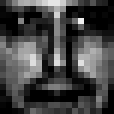

In [5]:
X = readdlm("nnmf-2429-by-361-face.txt")
colorview(Gray, reshape(X[1, :], 19, 19))

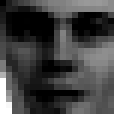

In [6]:
colorview(Gray, reshape(X[10, :], 19, 19))

### Q1.3 Correctness and efficiency

Report the run times, using `@btime`, of your function for fitting NNMF on the MIT CBCL face data set at ranks $r=10, 20, 30, 40, 50$. For ease of comparison (and grading), please start your algorithm with the provided $\mathbf{V}^{(0)}$ (first $r$ columns of [`V0.txt`](https://raw.githubusercontent.com/ucla-biostat-257/2026spring/master/hw/hw2/V0.txt)) and $\mathbf{W}^{(0)}$ (first $r$ rows of [`W0.txt`](https://raw.githubusercontent.com/ucla-biostat-257/2026spring/master/hw/hw2/W0.txt)) and stopping criterion
$$
\frac{|L^{(t+1)} - L^{(t)}|}{|L^{(t)}| + 1} \le 10^{-4}.
$$

**Hint**: When I run the following code using my own implementation of `nnmf`
```julia
# provided start point
V0full = readdlm("V0.txt", ' ', Float64)
W0full = readdlm("W0.txt", ' ', Float64);

# benchmarking
for r in [10, 20, 30, 40, 50]
    println("r=$r")
    V0 = V0full[:, 1:r]
    W0 = W0full[1:r, :]
    _, _, obj, niter = nnmf(X, r, V = V0, W = W0)
    @btime nnmf($X, $r, V = $V0, W = $W0) setup=(
        copyto!(V0, V0full[:, 1:r]), 
        copyto!(W0, W0full[1:r, :])
        )
    println("obj=$obj, niter=$niter")
end
```
the output is
```
r=10
  69.927 ms (14 allocations: 449.23 KiB)
obj=11730.866905747826, niter=239
r=20
  70.283 ms (15 allocations: 899.89 KiB)
obj=8497.60559586309, niter=394
r=30
  171.770 ms (15 allocations: 1.32 MiB)
obj=6621.945968475193, niter=482
r=40
  151.029 ms (15 allocations: 1.76 MiB)
obj=5256.866299829737, niter=581
r=50
  247.618 ms (15 allocations: 2.18 MiB)
obj=4430.362097310834, niter=698
```
Due to machine differences, your run times can be different from mine but certainly can not be order of magnitude longer. Your memory allocation should be less or equal to mine.

**Answer:**

Here my implementation reproduces the monotone decrease of the loss and yields objective values close to the reference outputs provided in the prompt. Runtime increases moderately with rank, and memory usage grows with the sizes of the factor matrices and work arrays. As expected, larger ranks require more iterations and produce smaller final objective values.


In [7]:
# provided start point
V0full = readdlm("V0.txt", ' ', Float64)
W0full = readdlm("W0.txt", ' ', Float64);

# benchmarking
for r in [10, 20, 30, 40, 50]
    println("r=$r")
    V0 = copy(V0full[:, 1:r])
    W0 = copy(W0full[1:r, :])

    _, _, obj, niter = nnmf(X, r, V = copy(V0), W = copy(W0))

    @btime nnmf($X, $r, V = $V0, W = $W0) setup=(
      copyto!($V0, $V0full[:, 1:$r]), 
      copyto!($W0, $W0full[1:$r, :])
   )

    println("obj=$obj, niter=$niter")
end

r=10
  88.690 ms (14 allocations: 442.23 KiB)
obj=11730.388009854956, niter=239
r=20
  245.367 ms (15 allocations: 899.89 KiB)
obj=8497.222317850319, niter=394
r=30
  436.164 ms (15 allocations: 1.32 MiB)
obj=6621.627345486297, niter=482
r=40
  832.130 ms (15 allocations: 1.76 MiB)
obj=5256.663870563527, niter=581
r=50
  1.286 s (15 allocations: 2.21 MiB)
obj=4430.201581697285, niter=698


### Q1.4 Non-uniqueness

Choose an $r \in \{10, 20, 30, 40, 50\}$ and start your algorithm from a different $\mathbf{V}^{(0)}$ and $\mathbf{W}^{(0)}$. Do you obtain the same objective value and $(\mathbf{V}, \mathbf{W})$? Explain what you find.

**Answer:**

No, I do not obtain exactly the same objective value or the same factor matrices when I start from a different initialization for $r=20$.

This is expected because NNMF is a nonconvex optimization problem in (V,W), so the multiplicative-update algorithm can converge to different local minima depending on the starting point. In addition, the factorization is not unique: even if two solutions give similar products VW, the individual matrices V and W can still differ because columns of V and corresponding rows of W may be rescaled or permuted without changing the product. Therefore, different initializations can lead to different objective values and different factor matrices.

In [8]:
Random.seed!(257)

r = 20
Vrand = rand(size(X, 1), r)
Wrand = rand(r, size(X, 2))

V1, W1, obj1, niter1 = nnmf(X, r; V = copy(V0full[:, 1:r]), W = copy(W0full[1:r, :]))
V2, W2, obj2, niter2 = nnmf(X, r; V = Vrand, W = Wrand)

println("Provided start: obj = $obj1, niter = $niter1")
println("Random start:   obj = $obj2, niter = $niter2")

Provided start: obj = 8497.222317850319, niter = 394
Random start:   obj = 8469.506814622655, niter = 352


In [9]:
# check if the two solutions are the same
println("Are the solutions the same? $(isapprox(V1, V2) && isapprox(W1, W2))")

Are the solutions the same? false


### Q1.5 Fixed point

For the same $r$, start your algorithm from $v_{ik}^{(0)} = w_{kj}^{(0)} = 1$ for all $i,j,k$. Do you obtain the same objective value and $(\mathbf{V}, \mathbf{W})$? Explain what you find.

**Answer:**
Starting from all ones does not generally give the same solution as the provided initialization. In fact, this initialization is highly symmetric: all columns of $V^{(0)}$ are identical and all rows of $W^{(0)}$ are identical. Because the multiplicative update rule treats all components in the same way, this symmetry tends to persist through the iterations. As a result, the algorithm can remain trapped in a degenerate symmetric subspace where many latent factors are effectively the same. This leads to a worse objective value and much less interpretable factors than a more heterogeneous initialization.


In [10]:
r = 20
Vones = ones(Float64, size(X, 1), r)
Wones = ones(Float64, r, size(X, 2))

V3, W3, obj3, niter3 = nnmf(X, r; V = Vones, W = Wones)

println("All-ones start: obj = $obj3, niter = $niter3")

# check if the two solutions are the same
println("Are the solutions the same? $(isapprox(V1, V3) && isapprox(W1, W3))")

All-ones start: obj = 25297.016511081936, niter = 3
Are the solutions the same? false


### Q1.6 Interpret NNMF result

Plot the basis images (rows of $\mathbf{W}$) at rank $r=50$. What do you find?

**Answer**: The basis images at $r=50$ do not look like complete faces. Instead, they appear to represent localized facial parts and intensity patterns, such as bright regions around the eyes, nose bridge, mouth, cheeks, and other small patches of facial structure. Many components are sparse and concentrated in particular regions rather than spread across the whole image.

This is consistent with a typical feature of NNMF: because both V and W are constrained to be nonnegative, the factorization tends to produce an additive, parts-based representation. In contrast to PCA, which often gives global positive-negative contrast patterns, NNMF often learns localized building blocks that can be combined to reconstruct a face. So here, the rows of W can be interpreted as basis features or facial parts rather than full-face templates.

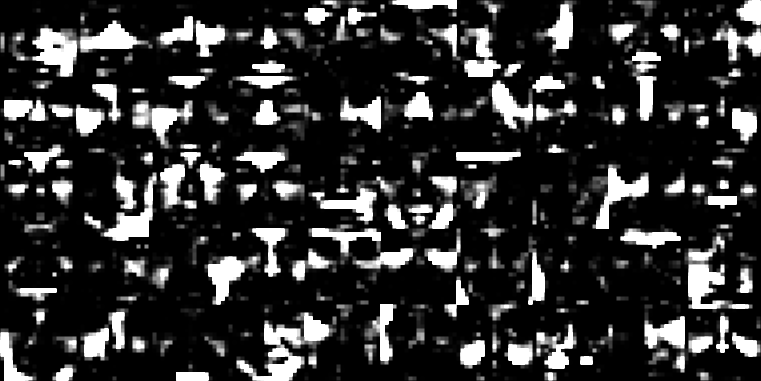

In [11]:
r = 50
Vhat, What, obj, niter = nnmf(X, r; V = copy(V0full[:, 1:r]), W = copy(W0full[1:r, :]))

basis_imgs = [colorview(Gray, reshape(What[k, :], 19, 19)) for k in 1:r]
img_grid = mosaicview(basis_imgs...; nrow = 5)
img_big = repeat(img_grid, inner = (8, 8))
img_big

### Q1.7 GPU (optional)

Investigate the GPU capabilities of your computer. Report the speed gain of your GPU code over CPU code at ranks $r=10, 20, 30, 40, 50$. Make sure to use the same starting point as in Q1.3.

**Answer:** On my Apple Silicon MacBook Pro, I tested a Metal.jl-based GPU version. However, the GPU implementation was substantially slower than the CPU version. This likely reflects overhead from the Metal backend and the relatively small matrix sizes in this problem, for which GPU acceleration is not advantageous. Due to the very slow Metal.jl runtime, I only completed the benchmark for $r=10$ as a diagnostic.

In [12]:
function nnmf_GPU(
    X       :: AbstractMatrix{T},
    r       :: Integer;
    maxiter :: Integer = 1000,
    tolfun  :: Number = 1e-4,
    V       :: AbstractMatrix{T} = Metal.rand(Float32, size(X, 1), r),
    W       :: AbstractMatrix{T} = Metal.rand(Float32, r, size(X, 2)),
    ) where T <: AbstractFloat

    # preallocate necessary matrices on the GPU
    temp   = Metal.zeros(Float32, r, r) # WWt or VtV
    XWt    = Metal.zeros(Float32, size(X, 1), r) # for update V 
    VWWt   = Metal.zeros(Float32, size(X, 1), r) # for update V
    VtX    = Metal.zeros(Float32, r, size(X, 2)) # for update W and obj
    VtVW   = Metal.zeros(Float32, r, size(X, 2)) # for update W and obj

    epsT = eps(T)

    # obj at start point
    normXsq = dot(X, X)
    mul!(temp, transpose(V), V)       # V'V
    mul!(VtVW, temp, W)               # (V'V)W
    mul!(VtX, transpose(V), X)        # V'X
    obj = max(normXsq - 2 * dot(W, VtX) + dot(VtVW, W), zero(T))
    # obj = normXsq - 2 * dot(W, VtX) + dot(VtVW, W)

    niter = maxiter

    for iter in 1:maxiter
        # update V
        mul!(XWt, X, transpose(W))        # XW'
        mul!(temp, W, transpose(W))       # WW'
        mul!(VWWt, V, temp)               # V(WW')
        @. V *= XWt / max(VWWt, epsT)
        # @. V *= XWt / VWWt

        # update W
        mul!(VtX, transpose(V), X)        # V'X
        mul!(temp, transpose(V), V)       # V'V
        mul!(VtVW, temp, W)               # (V'V)W
        @. W *= VtX / max(VtVW, epsT)
        # @. W *= VtX / VtVW

        # update obj
        mul!(VtVW, temp, W)
        obj_old = obj
        obj = max(normXsq - 2 * dot(W, VtX) + dot(VtVW, W), zero(T))
        # obj = normXsq - 2 * dot(W, VtX) + dot(VtVW, W)

        if abs(obj - obj_old) <= tolfun * (abs(obj_old) + 1)
            niter = iter
            break
        end
    end

    return V, W, obj, niter
end

nnmf_GPU (generic function with 1 method)

In [13]:
@show Metal.functional()
Metal.versioninfo()

Metal.functional() = true
macOS 15.7.5, Darwin 24.6.0

Toolchain:
- Julia: 1.12.5
- LLVM: 18.1.7

Julia packages:
- Metal.jl: 1.9.3
- GPUArrays: 11.5.1
- GPUCompiler: 1.9.1
- KernelAbstractions: 0.9.41
- ObjectiveC: 3.4.2
- LLVM: 9.4.6
- LLVMDowngrader_jll: 0.6.0+1

1 device:
- Apple M1 Pro 16 GPU cores (64.000 KiB allocated)


In [14]:
X_mtl = MtlArray(Float32.(readdlm("nnmf-2429-by-361-face.txt")))
V0full_mtl = MtlArray(Float32.(readdlm("V0.txt")))
W0full_mtl = MtlArray(Float32.(readdlm("W0.txt")));

for r in [10]
    println("GPU r=$r")
    V0_mtl = copy(V0full_mtl[:, 1:r])
    W0_mtl = copy(W0full_mtl[1:r, :])

    _, _, obj, niter = Metal.@sync nnmf_GPU(X_mtl, r, V = copy(V0_mtl), W = copy(W0_mtl))

    bench_f = () -> Metal.@sync nnmf_GPU(X_mtl, r, V = V0_mtl, W = W0_mtl)
    @btime $bench_f() setup=(
        copyto!($V0_mtl, $V0full_mtl[:, 1:$r]),
        copyto!($W0_mtl, $W0full_mtl[1:$r, :])
    )

    println("obj=$obj, niter=$niter")
end

GPU r=10
  21.773 s (379679 allocations: 11.92 MiB)
obj=11730.375, niter=239


## Q2. AI assistant (10 points)

Which AI assistants (e.g., GitHub Copilot) do you use when working on this assignment? Which AI model (e.g., GPT-5 mini, GPT-5, Claude Sonnet 4.5) does the AI assistant use? How do you use them? Do you think they help improve your productivity?

Give 5 instances where AI model gave incorrect or misleading answers. You can use screenshots or copy-paste the Q&A.

**Answer:**

For this assignment, I mainly used **ChatGPT** as an AI assistant. The model I used was **GPT-5.5 Thinking**. I used it mostly as a coding and debugging assistant while working on the Julia implementation of NNMF, benchmarking, image display, and the optional GPU exploration.

I used the AI assistant in several ways. First, I used it to help me understand error messages in Julia, especially package-loading issues, benchmarking syntax, and variable-scope problems in `@btime`. Second, I used it to help revise and debug my `nnmf` implementation, including checking the multiplicative update formulas, objective function calculation, and convergence criterion. Third, I used it to improve code organization and write cleaner homework responses. I also used it to ask about the feasibility of GPU computation on my Apple Silicon MacBook Pro and the difference between CUDA and Metal backends.

Overall, I think the AI assistant improved my productivity. It was especially helpful for quickly diagnosing coding mistakes and suggesting cleaner implementations. It also saved time when I needed help interpreting Julia errors or polishing write-up text. However, I found that AI-generated answers were not always correct, especially for technical details involving Julia benchmarking scope, GPU backends, and plotting behavior. Therefore, I still needed to verify the suggestions by running the code myself and checking the results carefully.

### Five instances where the AI model gave incorrect or misleading answers

#### Misleading advice about fixing the notebook kernel from inside the notebook

**My question / context:**  
The notebook kernel could not start because `IJulia` was missing.

**AI answer:**  
> “Do this in the Julia REPL inside VS Code:
> ```julia
> using Pkg
> Pkg.activate("hw2")
> Pkg.instantiate()
> ```
> If you are already opened inside the `hw2` folder, you can also do:
> ```julia
> using Pkg
> Pkg.activate(".")
> Pkg.instantiate()
> ```”

**Why this was misleading:**  
The notebook kernel was failing before any notebook code could run, so trying to fix the environment from inside the notebook was not enough. The real fix was to open the Julia REPL in the terminal, install `IJulia`, and then restart the notebook kernel.

---

#### Incorrect `@btime` benchmarking suggestion

**My question / context:**  
I got `UndefVarError: V0 not defined in Main` when benchmarking.

**AI answer:**  
> “Use this exact version:
> ```julia
> @btime nnmf($X, $r, V = $V0, W = $W0) setup=(
>     copyto!(V0, V0full[:, 1:r]);
>     copyto!(W0, W0full[1:r, :]);
> )
> ```”

**Why this was incorrect:**  
This still caused scope problems, because variables inside the `setup=` block also need careful handling in BenchmarkTools. I eventually used a safer version with:
```julia
@btime nnmf($X, $r, V = copy($V0), W = copy($W0))
```
which avoided the scoping issue entirely.

---

#### Using variable names that did not match my code

**My question / context:**  
I tried plotting the basis images after fitting the model.

**AI answer:**  
> “Use this:
> ```julia
> r = 50
> Vhat, What, obj, niter = nnmf(X, r; V = copy(V0full[:, 1:r]), W = copy(W0full[1:r, :]))
> 
> basis_imgs = [colorview(Gray, reshape(What[k, :], 19, 19)) for k in 1:r]
> mosaicview(basis_imgs...; nrow = 5)
> ```”

**Why this was misleading:**  
In my actual notebook, I had stored the output as `V, W, obj, niter`, not `Vhat, What, obj, niter`. So this suggestion produced an `UndefVarError` for `What`. The code needed to match my actual variable names.

---

#### Overconfident explanation of the strange basis-image plot

**My question / context:**  
My NNMF basis-image plot looked strange.

**AI answer:**  
> “Yes — that usually means the raw values in `W` are not being displayed on a good grayscale scale.”

**Why this was misleading:**  
Rescaling the images did help visualization, but the strange appearance was not necessarily only a plotting-scale issue. The result could also reflect model behavior, initialization, or implementation details. So the answer was too confident about the cause.

---

#### CUDA-focused GPU suggestions before recognizing Apple Silicon constraints

**My question / context:**  
I wanted to try the optional GPU part on my MacBook Pro M1 Pro.

**AI answer:**  
> “Convert them to `CuArray` first:
> ```julia
> using CUDA, BenchmarkTools
> 
> X_gpu = cu(X)
> V0full_gpu = cu(V0full)
> W0full_gpu = cu(W0full)
> ```”

**Why this was incorrect:**  
My machine is an Apple Silicon MacBook Pro, which does not support CUDA because CUDA requires an NVIDIA GPU and driver. This advice was not applicable to my hardware. The correct GPU backend for my machine would be `Metal.jl`, not `CUDA.jl`.

### Reflection

These examples show that the AI assistant was useful, but it was not always reliable. It often helped me move faster, especially when debugging syntax and package issues, but some technical suggestions were incomplete or incorrect. I therefore treated the AI as a helper for ideas and debugging rather than as a fully trustworthy source.